In [16]:
import jax
from jax import vmap
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from DGPs import DGP_univariate, DGP_high_dim_X, DGP_high_dim_M, DGP_high_dim_MX, DGP_high_dim_Y, DGP_binary

from propensities import estimate_propensity
from utils import Array,Scalar
from KRR_utils import learn_hyperparams, ard_median_heuristic
from experiments import run_convergence_experiment
from embeddings import mu_y_amx, MMD_plugin

In [2]:
dim=1
treatment=1
method='table'
A_truth,M_truth,X_truth,Y_truth = DGP_binary(10000,seed=101,dim=dim,gt=True,a0=treatment)

A,M,X,Y = DGP_binary(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

In [3]:
def probs(logit):
    return jnp.pow(jnp.ones((1,))+jnp.exp(logit),-1)

def X_to_logit(X):
    return 2*X-1

def AX_to_logit(X):
    A=X[0]
    X=X[1]
    return 2*A+2*X-2

In [4]:
x_opts = jnp.array([[0],
                    [1]])
ax_opts = np.array([[0,0],
                    [0,1],
                    [1,0],
                    [1,1]])
amx_opts = jnp.array([[0,0,0],
                      [0,1,0],
                      [1,0,0],
                      [1,1,0],
                      [0,0,1],
                      [0,1,1],
                      [1,0,1],
                      [1,1,1]])

In [5]:
x_true_probs=jnp.zeros((x_opts.shape[0],2))
ax_true_probs=jnp.zeros((ax_opts.shape[0],2))

for i in range(x_opts.shape[0]):
    prob=probs(X_to_logit(x_opts[i,:])).item()
    x_true_probs = x_true_probs.at[i,0].set(1-prob)
    x_true_probs = x_true_probs.at[i,1].set(prob)

for i in range(ax_opts.shape[0]):
    prob=probs(AX_to_logit(ax_opts[i,:])).item()
    ax_true_probs = ax_true_probs.at[i,0].set(1-prob)
    ax_true_probs = ax_true_probs.at[i,1].set(prob)

In [6]:
def propensity_convergence(DGP,
                               n:int,
                               seed:int=0,
                               dim:int=1,
                               x_method:str='logistic',
                               mx_method:str='logistic',
                               x_true_probs:Array=x_true_probs,
                               ax_true_probs:Array=ax_true_probs):
    x_opts = jnp.array([[0],
                        [1]])
    ax_opts = np.array([[0,0],
                        [0,1],
                        [1,0],
                        [1,1]])
    
    A,M,X,Y = DGP(n,seed=seed,dim=dim)
    a_x =estimate_propensity(np.array(A),np.array(X),method=x_method)
    m_ax = estimate_propensity(np.array(M),np.concatenate((np.array(A),np.array(X)),axis=1),method=mx_method)

    p_a_x_array=jnp.array(a_x.predict_proba(np.array(x_opts)))
    p_m_ax_array=jnp.array(m_ax.predict_proba(np.array(ax_opts)))

    return p_a_x_array-x_true_probs,p_m_ax_array-ax_true_probs
    
    

In [7]:
err_ax,err_max=propensity_convergence(DGP_binary,1000,seed=2,x_method='table',mx_method='table')

print(jnp.linalg.norm(jnp.abs(err_ax[:,0])))
print(jnp.linalg.norm(jnp.abs(err_max[:,0])))

0.02024653
0.017902123


In [19]:
def conditional_DGP(AMX:Array,n:int,seed:int=0):
    key=jax.random.key(seed)
    A=AMX[0]
    M=AMX[1]
    X=AMX[2]
    return M+X+jax.random.normal(key,shape=(n,1))

def embedding_convergence(n:int,seed:int=0):
    opts = jnp.array([[0,0,0],
                          [0,1,0],
                          [1,0,0],
                          [1,1,0],
                          [0,0,1],
                          [0,1,1],
                          [1,0,1],
                          [1,1,1]])

    A,M,X,Y = DGP_binary(n,seed=seed)

    embedder=mu_y_amx()
    embedder.train(jnp.concatenate((A,M,X),axis=1))
    div_list=jnp.empty((opts.shape[0],))

    for i in range(opts.shape[0]):
        AMX=jnp.atleast_2d(opts[i,:])
        true_Y=conditional_DGP(opts[i,:],n=10000,seed=101)
        weights = embedder.predict(AMX)
        div_list = div_list.at[i].set(jnp.sqrt(MMD_plugin(Y,true_Y,weights)))
    return div_list
        

    

In [20]:
print(embedding_convergence(1000))

[0.8093771 0.8324336 0.8964157 0.8838928 0.8974343 0.8992992 0.8023856
 0.9371264]


In [51]:
n_list=[250,500,1000,2000,4000,8000,16000,32000]
num_seeds=200
ax_mat=jnp.zeros((len(n_list),num_seeds))
max_mat=jnp.zeros((len(n_list),num_seeds))
for i in range(len(n_list)):
    n=n_list[i]
    print('n: ',n)
    for k in range(num_seeds):
        if k%50 == 0:
            print('seed: ',k)
        err_ax,err_max=propensity_convergence(DGP_binary,n=n,seed=k,x_method='table',mx_method='table')
        ax_mat = ax_mat.at[i,k].set(jnp.linalg.norm(jnp.abs(err_ax[:,0])))
        max_mat = max_mat.at[i,k].set(jnp.linalg.norm(jnp.abs(err_max[:,0])))

with open('results/propensity_convergence.npy', 'wb') as f:
    jnp.save(f, ax_mat)
    jnp.save(f, max_mat)

n:  250
seed:  0
seed:  50
seed:  100
seed:  150
n:  500
seed:  0
seed:  50
seed:  100
seed:  150
n:  1000
seed:  0
seed:  50
seed:  100
seed:  150
n:  2000
seed:  0
seed:  50
seed:  100
seed:  150
n:  4000
seed:  0
seed:  50
seed:  100
seed:  150
n:  8000
seed:  0
seed:  50
seed:  100
seed:  150
n:  16000
seed:  0
seed:  50
seed:  100
seed:  150
n:  32000
seed:  0
seed:  50
seed:  100
seed:  150


In [23]:
n_list=[250,500,1000,2000,4000,8000]
num_seeds=200
mu_mat=jnp.zeros((len(n_list),num_seeds,8))
for i in range(len(n_list)):
    n=n_list[i]
    print('n: ',n)
    for k in range(num_seeds):
        if k%50 == 0:
            print('seed: ',k)
        err=embedding_convergence(n=n,seed=k)
        mu_mat = mu_mat.at[i,k,:].set(err)

with open('results/embedding_convergence.npy', 'wb') as f:
    jnp.save(f, mu_mat)

n:  250
seed:  0
seed:  50
seed:  100
seed:  150
n:  500
seed:  0
seed:  50
seed:  100
seed:  150
n:  1000
seed:  0
seed:  50
seed:  100
seed:  150
n:  2000
seed:  0
seed:  50
seed:  100
seed:  150
n:  4000
seed:  0
seed:  50
seed:  100
seed:  150
n:  8000
seed:  0
seed:  50
seed:  100
seed:  150


In [24]:
print(ax_mat.mean(axis=1))
print(ax_mat.std(axis=1))

[0.00138376 0.00087907 0.00073221 0.00052041 0.00034843 0.00025671
 0.00018441]
[0.01076694 0.00686698 0.00545304 0.00379536 0.00250008 0.00185546
 0.00134083]


<>:33: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:36: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:33: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:36: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/ym/ygcsp08s7fgc4wgspd4lk4lw0000gn/T/ipykernel_48761/2722087001.py:33: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  axs[1,0].set_ylabel("$\sqrt{n}$-mean")
/var/folders/ym/ygcsp08s7fgc4wgspd4lk4lw0000gn/T/ipykernel_48761/2722087001.py:36: SyntaxWarning: "\s" is an inva

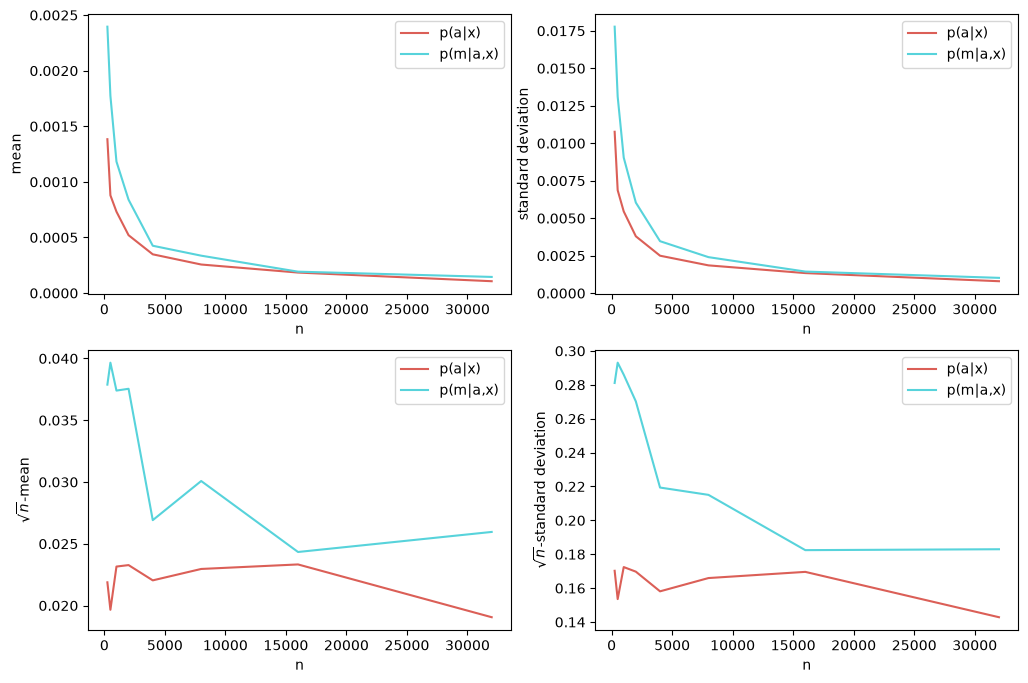

In [52]:
n_arr=jnp.array([250,500,1000,2000,4000,8000,16000,32000])
color_list=sns.color_palette("hls", 2)
fig, axs = plt.subplots(2, 2, figsize=(12, 8))


means_ax=ax_mat.mean(axis=1)
stds_ax=ax_mat.std(axis=1)
ax_color=color_list[0]
ax_label='p(a|x)'

axs[0,0].plot(n_arr,means_ax, color=ax_color, label=ax_label)
axs[0,1].plot(n_arr,stds_ax, color=ax_color, label=ax_label)
axs[1,0].plot(n_arr,np.sqrt(n_arr)*means_ax, color=ax_color, label=ax_label)
axs[1,1].plot(n_arr,np.sqrt(n_arr)*stds_ax, color=ax_color, label=ax_label)
        
means_max=max_mat.mean(axis=1)
stds_max=max_mat.std(axis=1)
max_color=color_list[1]
max_label='p(m|a,x)'

axs[0,0].plot(n_arr,means_max, color=max_color, label=max_label)
axs[0,1].plot(n_arr,stds_max, color=max_color, label=max_label)
axs[1,0].plot(n_arr,np.sqrt(n_arr)*means_max, color=max_color, label=max_label)
axs[1,1].plot(n_arr,np.sqrt(n_arr)*stds_max, color=max_color, label=max_label)

axs[0,0].set_xlabel("n")
axs[0,0].set_ylabel("mean")
axs[0,0].legend()
axs[0,1].set_xlabel("n")
axs[0,1].set_ylabel("standard deviation")
axs[0,1].legend()
axs[1,0].set_xlabel("n")
axs[1,0].set_ylabel("$\sqrt{n}$-mean")
axs[1,0].legend()
axs[1,1].set_xlabel("n")
axs[1,1].set_ylabel("$\sqrt{n}$-standard deviation")
axs[1,1].legend()

    
plt.savefig('figures/propensity_convergence_results.png')
plt.show()
plt.close()

<>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:27: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:27: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/ym/ygcsp08s7fgc4wgspd4lk4lw0000gn/T/ipykernel_48761/3696923603.py:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  axs[1,0].set_ylabel("$\sqrt{n}$-mean")
/var/folders/ym/ygcsp08s7fgc4wgspd4lk4lw0000gn/T/ipykernel_48761/3696923603.py:27: SyntaxWarning: "\s" is an inva

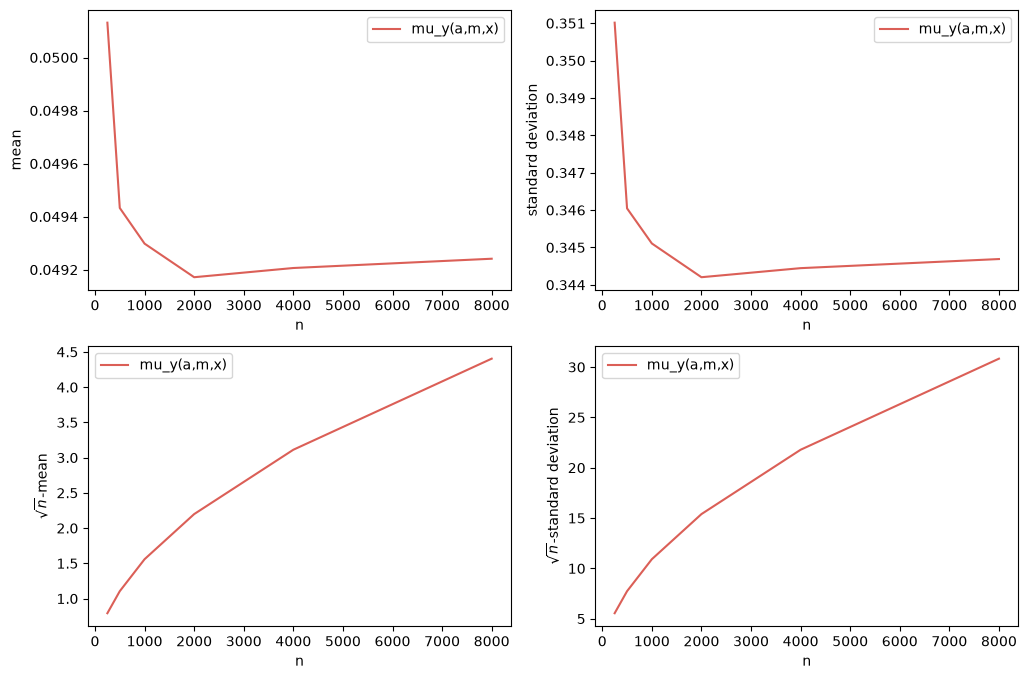

In [58]:
n_arr=jnp.array([250,500,1000,2000,4000,8000])
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

mat=jnp.linalg.norm(mu_mat,axis=2)
#print(mat.shape)

means=mat.mean(axis=1)
stds=mat.std(axis=1)
color=color_list[0]
label='mu_y(a,m,x)'

axs[0,0].plot(n_arr,means, color=color, label=label)
axs[0,1].plot(n_arr,stds, color=color, label=label)
axs[1,0].plot(n_arr,np.sqrt(n_arr)*means, color=color, label=label)
axs[1,1].plot(n_arr,np.sqrt(n_arr)*stds, color=color, label=label)

axs[0,0].set_xlabel("n")
axs[0,0].set_ylabel("mean")
axs[0,0].legend()
axs[0,1].set_xlabel("n")
axs[0,1].set_ylabel("standard deviation")
axs[0,1].legend()
axs[1,0].set_xlabel("n")
axs[1,0].set_ylabel("$\sqrt{n}$-mean")
axs[1,0].legend()
axs[1,1].set_xlabel("n")
axs[1,1].set_ylabel("$\sqrt{n}$-standard deviation")
axs[1,1].legend()

    
plt.savefig('figures/embedding_convergence_results.png')
plt.show()
plt.close()